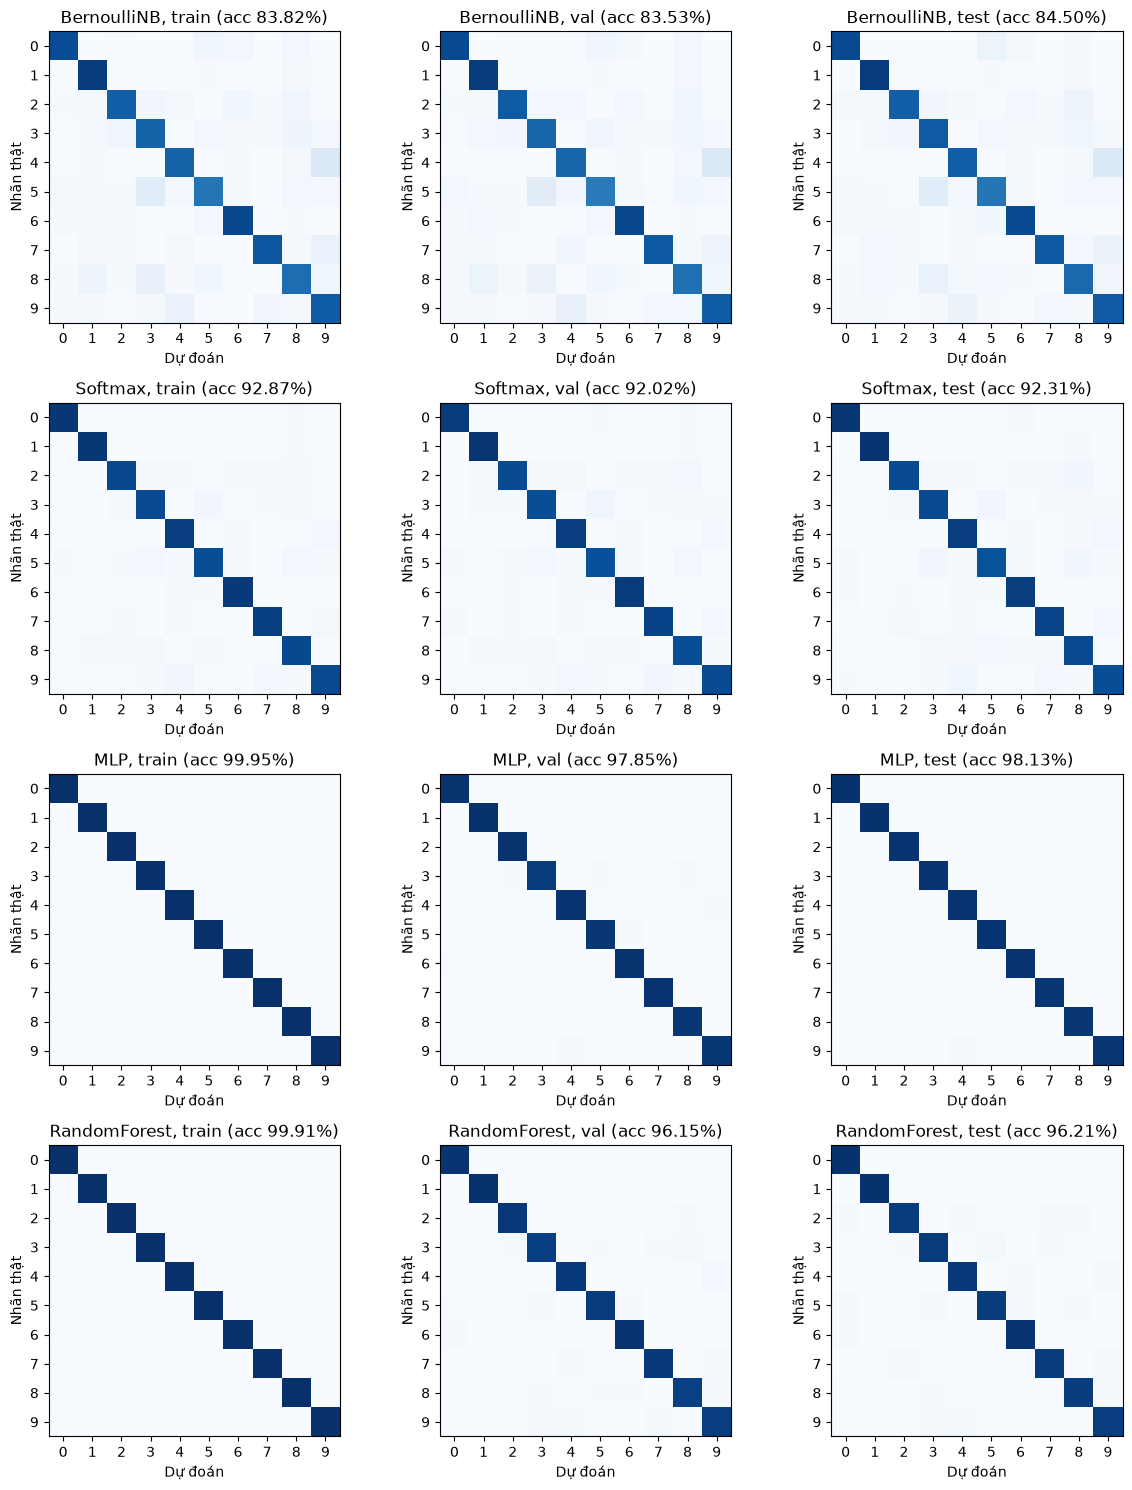

In [1]:
import sys, json
from pathlib import Path
p = Path.cwd()
while not (p / "data.py").exists():
    p = p.parent
sys.path.insert(0, str(p))
import numpy as np, matplotlib.pyplot as plt

res = json.load(open(p / "results" / "metrics.json"))
main = ["BernoulliNB", "Softmax", "MLP", "RandomForest"]
fig, ax = plt.subplots(4, 3, figsize=(12, 15))
for i, n in enumerate(main):
    for j, s in enumerate(["train", "val", "test"]):
        C = np.array(res[n][s]["confusion_matrix"], dtype=float)
        ax[i, j].imshow(C / C.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        ax[i, j].set_title(f"{n}, {s} (acc {res[n][s]['accuracy']*100:.2f}%)")
        ax[i, j].set_xlabel("Dự đoán"); ax[i, j].set_ylabel("Nhãn thật")
        ax[i, j].set_xticks(range(10)); ax[i, j].set_yticks(range(10))
plt.tight_layout()
plt.savefig(p / "report" / "confusion_all_sets.png", dpi=150)
plt.show()